In [1]:
# ========== IMPORTS ==========
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset
import matplotlib.pyplot as plt
import sys
import os
import glob
from pathlib import Path
from sklearn.preprocessing import StandardScaler

# Add parent directory to path to access utils
sys.path.append(str(Path.cwd().parent))

# Import custom modules
from utils.simple_lds_loss import SimpleLDSLoss
from utils.reproducibility_utils import seed_everything
from utils.band_mapping import load_band_mapping
from utils.kaggle_metric import score
from utils.data_loading import load_data, load_test_data  # ← KEY: Pipeline-based loading!

# Load band mapping dictionary
shot_band_mapping = load_band_mapping()

# ⚡ GPU CHECK & PERFORMANCE OPTIMIZATIONS
print("\n" + "="*80)
print("🎮 GPU DETECTION")
print("="*80)

if torch.cuda.is_available():
    gpu_name = torch.cuda.get_device_name(0)
    gpu_memory = torch.cuda.get_device_properties(0).total_memory / 1024**3  # GB
    gpu_capability = torch.cuda.get_device_capability(0)
    
    print(f"✅ CUDA Available: YES")
    print(f"   GPU: {gpu_name}")
    print(f"   Memory: {gpu_memory:.1f} GB")
    print(f"   Compute Capability: {gpu_capability[0]}.{gpu_capability[1]}")
    
    # Check if RTX 4090
    if "4090" in gpu_name:
        print(f"   🚀 RTX 4090 detected! Excellent choice for deep learning!")
    
    # Enable performance optimizations
    torch.backends.cudnn.benchmark = True
    torch.autograd.set_detect_anomaly(False)
    
    # Enable TF32 for Ampere/Ada Lovelace GPUs (RTX 30xx/40xx, A100, etc.)
    if gpu_capability[0] >= 8:
        torch.backends.cuda.matmul.allow_tf32 = True
        torch.backends.cudnn.allow_tf32 = True
        print(f"   ⚡ TF32 enabled (2x speedup for matrix operations)")
    
    print(f"   ⚡ cuDNN benchmark enabled (auto-selects fastest algorithms)")
else:
    print(f"❌ CUDA NOT Available - using CPU")
    print(f"   ⚠️  Training will be MUCH slower on CPU!")

print("="*80)
print("✅ All imports successful")
print(f"✅ Loaded {len(shot_band_mapping)} sideslip band mappings")
print(f"✅ Pipeline-based data loading ready (load_data, load_test_data)")



🎮 GPU DETECTION
✅ CUDA Available: YES
   GPU: NVIDIA GeForce RTX 4090
   Memory: 24.0 GB
   Compute Capability: 8.9
   🚀 RTX 4090 detected! Excellent choice for deep learning!
   ⚡ TF32 enabled (2x speedup for matrix operations)
   ⚡ cuDNN benchmark enabled (auto-selects fastest algorithms)
✅ All imports successful
✅ Loaded 234 sideslip band mappings
✅ Pipeline-based data loading ready (load_data, load_test_data)


In [2]:
# ========== SET SEED FOR REPRODUCIBILITY ==========
seed_everything(42)
print("✅ Seed set to 42")

✅ Seed set to 42


In [3]:
class RNN(nn.Module):
    """
    Flexible Recurrent Neural Network for sideSlip prediction.
    Supports: RNN, LSTM, GRU, BiLSTM, BiGRU
    """

    def __init__(self, 
                 input_size,          # Anzahl der Features
                 hidden_size=64,      # Größe der RNN-Units
                 num_layers=1,        # Anzahl der RNN-Layers
                 fc_units=64,         # Anzahl Units der Fully Connected Layer
                 output_size=1,       # Dimension des Outputs
                 activation_fct=nn.ReLU(), 
                 dropout=[0.2, 0, 0], # Dropouts: [input, nach RNN, nach FC]
                 rnn_type='RNN',      # 'RNN', 'LSTM', 'GRU', 'BiLSTM', 'BiGRU'
                 rnn_nonlinearity='tanh',  # nur für RNN
                 bidirectional=False  # Bidirektional (wird von rnn_type überschrieben)
                 ):
        super(RNN, self).__init__()

        self.dropout1 = nn.Dropout(dropout[0])
        self.dropout2 = nn.Dropout(dropout[1])
        self.dropout3 = nn.Dropout(dropout[2])
        self.activation_fct = activation_fct
        
        # Auto-detect bidirectional from rnn_type
        if rnn_type.upper().startswith('BI'):
            bidirectional = True
            rnn_type = rnn_type[2:]  # Remove 'Bi' prefix
        
        self.bidirectional = bidirectional
        self.rnn_type = rnn_type.upper()
        
        # Calculate output size (bidirectional doubles the hidden size)
        rnn_output_size = hidden_size * 2 if bidirectional else hidden_size

        # RNN Layer
        if self.rnn_type == 'RNN':
            self.rnn_layer = nn.RNN(input_size=input_size,
                                    hidden_size=hidden_size,
                                    num_layers=num_layers,
                                    nonlinearity=rnn_nonlinearity,
                                    batch_first=True,
                                    bidirectional=bidirectional)
        elif self.rnn_type == 'LSTM':
            self.rnn_layer = nn.LSTM(input_size=input_size,
                                     hidden_size=hidden_size,
                                     num_layers=num_layers,
                                     batch_first=True,
                                     bidirectional=bidirectional)
        elif self.rnn_type == 'GRU':
            self.rnn_layer = nn.GRU(input_size=input_size,
                                    hidden_size=hidden_size,
                                    num_layers=num_layers,
                                    batch_first=True,
                                    bidirectional=bidirectional)
        else:
            raise ValueError(f"Unsupported rnn_type {rnn_type}")

        # Fully Connected Layer (adjust input size for bidirectional)
        self.fc = nn.Linear(rnn_output_size, fc_units)
        self.output_layer = nn.Linear(fc_units, output_size)

    def forward(self, x):
        x = self.dropout1(x)
        x, out = self.rnn_layer(x)  # output shape: (batch, seq_len, hidden_size * num_directions)
        x = x[:, -1, :]            # nur letzter Zeitschritt
        x = self.dropout2(x)
        x = self.activation_fct(self.fc(x))
        x = self.dropout3(x)
        x = self.output_layer(x)
        return x, out


In [4]:
# ========== LOAD DATA USING PIPELINE (FILE-BASED SPLIT) ==========
print("\n" + "="*80)
print("📂 LOADING DATA WITH PIPELINE - FILE-BASED VALIDATION SPLIT")
print("="*80)

# Import the data loading function
from utils.data_loading import load_data_file_based, load_test_data

# Define parameters
drop_columns = ["sideSlip", "vyCG", "time", "longitude", "latitude"]
target_column = "sideSlip"
threshold_column = "vxCG"
threshold_value = 3.0
sequence_length = 20
batch_size = 64

# 🎯 FILE-BASED SPLIT: Use train_part_006.csv as validation
train_path = "../datasets_challenge/train"
val_file = "train_part_006.csv"

print(f"Loading training data with file-based split...")
print(f"   Validation file: {val_file}")
print(f"   Training files: All others")

# Get all CSV files and split them
import glob
all_files = sorted(glob.glob(os.path.join(train_path, '*.csv')))
train_files = [f for f in all_files if val_file not in f]
val_files = [f for f in all_files if val_file in f]

print(f"\n📂 Files:")
print(f"   Training: {len(train_files)} files")
print(f"   Validation: {len(val_files)} files")

# Load data using the new file-based function
train_loader, val_loader, pipeline = load_data_file_based(
    train_files=train_files,
    val_files=val_files,
    columns_to_drop=drop_columns,
    sequence_length=sequence_length,
    threshold=True,
    threshold_value=threshold_value,
    threshold_column=threshold_column,
    target=target_column,
    batchsize=batch_size,
    scaling=True,
    seed=42,
    shuffle=True
)

print(f"\n✅ Data loaded with file-based split")
print(f"   Train batches: {len(train_loader)}")
print(f"   Val batches: {len(val_loader)}")

# Get one batch to extract dimensions
X_sample, y_sample = next(iter(train_loader))
input_size = X_sample.shape[2]  # Number of features

print(f"\n📊 Data Statistics:")
print(f"   Input features: {input_size}")
print(f"   Sequence length: {sequence_length}")
print(f"   Batch size: {batch_size}")
print(f"   Total train batches: {len(train_loader)}")
print(f"   Total val batches: {len(val_loader)}")
print(f"   Train/Val split: File-based ({len(train_files)} / {len(val_files)} files)")

print(f"\n💡 Pipeline handles: Thresholding → Scaling → Sequencing → Batching")
print(f"💡 Validation: {val_file} (separate file, not random split)")
print("="*80)



📂 LOADING DATA WITH PIPELINE - FILE-BASED VALIDATION SPLIT
Loading training data with file-based split...
   Validation file: train_part_006.csv
   Training files: All others

📂 Files:
   Training: 21 files
   Validation: 1 files
Train: ../datasets_challenge/train\train_part_001.csv
Train: ../datasets_challenge/train\train_part_002.csv
Train: ../datasets_challenge/train\train_part_003.csv
Train: ../datasets_challenge/train\train_part_004.csv
Train: ../datasets_challenge/train\train_part_005.csv
Train: ../datasets_challenge/train\train_part_007.csv
Train: ../datasets_challenge/train\train_part_008.csv
Train: ../datasets_challenge/train\train_part_007.csv
Train: ../datasets_challenge/train\train_part_008.csv
Train: ../datasets_challenge/train\train_part_009.csv
Train: ../datasets_challenge/train\train_part_010.csv
Train: ../datasets_challenge/train\train_part_011.csv
Train: ../datasets_challenge/train\train_part_012.csv
Train: ../datasets_challenge/train\train_part_009.csv
Train: ../dat

c:\Repos\mait_g2_drift_challenge\.venv\Lib\site-packages\sklearn\pipeline.py:61: FutureWarning: This Pipeline instance is not fitted yet. Call 'fit' with appropriate arguments before using other methods such as transform, predict, etc. This will raise an error in 1.8 instead of the current warning.
  warnings.warn(


In [5]:
# ========== DATALOADER CONFIGURATION (SAME AS basic_notebook_FIXED.ipynb) ==========
print("\n" + "="*80)
print("⚡ DATALOADER CONFIGURATION")
print("="*80)

# The DataLoaders are created by load_data() with SAME parameters as basic_notebook_FIXED.ipynb:
# - train_ratio = 0.98 (98% train, 2% validation)
# - batchsize = 64
# - shuffle = True (default for training)
# - seed = 42

print("✅ DataLoaders created by pipeline (SAME AS basic_notebook_FIXED.ipynb):")
print(f"   • Batch size: {batch_size}")
print(f"   • Train/Val split: 98% / 2%")
print(f"   • Shuffle: True (train), False (val)")
print(f"   • Fixed seed: 42 (reproducible shuffling)")
print(f"   • Threshold: {threshold_value} m/s on {threshold_column}")
print(f"   • Standardization: Applied via pipeline")
print(f"   • Sequence length: {sequence_length}")

print(f"\n💡 Configuration Details:")
print(f"   - train_ratio=0.98 → 98% Training, 2% Validation")
print(f"   - This matches basic_notebook_FIXED.ipynb exactly!")
print(f"   - Validation split is used for early stopping")

print(f"\n📊 Dataset Sizes:")
train_samples = 0
for batch_x, batch_y in train_loader:
    train_samples += len(batch_x)
val_samples = 0
if val_loader:
    for batch_x, batch_y in val_loader:
        val_samples += len(batch_x)

print(f"   • Train samples: {train_samples:,}")
print(f"   • Val samples: {val_samples:,}")
print(f"   • Total: {train_samples + val_samples:,}")

print("\n💡 Advantage: Test data will use SAME pipeline → exact same preprocessing!")
print("="*80)



⚡ DATALOADER CONFIGURATION
✅ DataLoaders created by pipeline (SAME AS basic_notebook_FIXED.ipynb):
   • Batch size: 64
   • Train/Val split: 98% / 2%
   • Shuffle: True (train), False (val)
   • Fixed seed: 42 (reproducible shuffling)
   • Threshold: 3.0 m/s on vxCG
   • Standardization: Applied via pipeline
   • Sequence length: 20

💡 Configuration Details:
   - train_ratio=0.98 → 98% Training, 2% Validation
   - This matches basic_notebook_FIXED.ipynb exactly!
   - Validation split is used for early stopping

📊 Dataset Sizes:
   • Train samples: 116,654
   • Val samples: 20,426
   • Total: 137,080

💡 Advantage: Test data will use SAME pipeline → exact same preprocessing!
   • Train samples: 116,654
   • Val samples: 20,426
   • Total: 137,080

💡 Advantage: Test data will use SAME pipeline → exact same preprocessing!


In [6]:
# ========== MODEL CONFIGURATION ==========
print("\n" + "="*80)
print("🏆 MODEL CONFIGURATION")
print("="*80)

device = "cuda" if torch.cuda.is_available() else "cpu"

# Architecture parameters
rnn_type = 'RNN'
hidden_size = 64
fc_units = 64
num_layers = 1
dropouts = [0, 0, 0]

# Training parameters
lr = 0.0008
weight_decay = 1e-4

# Scheduler parameters
scheduler_mode = 'min'
scheduler_factor = 0.5
scheduler_patience = 4
scheduler_min_lr = 1e-6

# Training configuration
num_epochs = 50
early_stop_thresh = 10

# Loss strategy - REDUCED LDS (trying to get Many-Shot < 0.2°)
use_lds_best = True
lds_ks = 5
lds_sigma = 2.0

# Create model with input_size from pipeline
model = RNN(input_size=input_size,  # ← Now using input_size from Zelle 4!
            hidden_size=hidden_size,
            num_layers=num_layers,
            fc_units=fc_units,
            dropout=dropouts,
            rnn_type=rnn_type,
            output_size=1)
model.to(device)

# ⚡ CRITICAL PERFORMANCE BOOST: Compile model with PyTorch 2.0+
# This can give 30-50% speedup with no code changes!
if torch.cuda.is_available() and hasattr(torch, 'compile'):
    try:
        print("⚡ Compiling model with torch.compile() for 30-50% speedup...")
        model = torch.compile(model, mode='max-autotune')
        print("   ✅ Model compiled successfully!")
    except Exception as e:
        print(f"   ⚠️  torch.compile() not available or failed: {e}")
        print("   → Continuing with standard model (still fast with AMP)")

criterion = nn.L1Loss()  # MAE Loss
optimizer = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)

# ========== LEARNING RATE SCHEDULER ==========
# ReduceLROnPlateau: Reduces LR when validation loss plateaus
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, 
    mode=scheduler_mode,
    factor=scheduler_factor,
    patience=scheduler_patience,
    min_lr=scheduler_min_lr
)

print(f"\n🏗️  Architecture:")
print(f"   - RNN Type: {rnn_type}")
print(f"   - Input Size: {input_size} (from pipeline)")
print(f"   - Hidden Size: {hidden_size}")
print(f"   - FC Units: {fc_units}")
print(f"   - Num Layers: {num_layers}")
print(f"   - Dropout: {dropouts}")
print(f"\n⚙️  Training:")
print(f"   - Learning Rate: {lr}")
print(f"   - Weight Decay: {weight_decay}")
print(f"   - Epochs: {num_epochs}")
print(f"   - Early Stopping: {early_stop_thresh} epochs")
print(f"\n🎯 Strategy:")
print(f"   - Loss: LDS (ks={lds_ks}, sigma={lds_sigma}) [REDUCED - targeting Many < 0.2°]")



🏆 MODEL CONFIGURATION
⚡ Compiling model with torch.compile() for 30-50% speedup...
   ✅ Model compiled successfully!

🏗️  Architecture:
   - RNN Type: RNN
   - Input Size: 22 (from pipeline)
   - Hidden Size: 64
   - FC Units: 64
   - Num Layers: 1
   - Dropout: [0, 0, 0]

⚙️  Training:
   - Learning Rate: 0.0008
   - Weight Decay: 0.0001
   - Epochs: 50
   - Early Stopping: 10 epochs

🎯 Strategy:
   - Loss: LDS (ks=5, sigma=2.0) [REDUCED - targeting Many < 0.2°]
   ✅ Model compiled successfully!

🏗️  Architecture:
   - RNN Type: RNN
   - Input Size: 22 (from pipeline)
   - Hidden Size: 64
   - FC Units: 64
   - Num Layers: 1
   - Dropout: [0, 0, 0]

⚙️  Training:
   - Learning Rate: 0.0008
   - Weight Decay: 0.0001
   - Epochs: 50
   - Early Stopping: 10 epochs

🎯 Strategy:
   - Loss: LDS (ks=5, sigma=2.0) [REDUCED - targeting Many < 0.2°]


In [7]:
# Training configuration
best_loss = np.inf  # Initialize with infinity
best_epoch = -1
best_model_state = None  # Will store the best model weights

# ========== RESET SEED FOR REPRODUCIBILITY ==========
seed_everything(42)  # Reset seed before training!
print("✅ Seed reset to 42 for reproducibility")

# ⚡ SETUP AMP FOR SPEED
use_amp = device == 'cuda'
scaler = torch.amp.GradScaler('cuda') if use_amp else None
print(f"⚡ AMP (Automatic Mixed Precision): {'ON' if use_amp else 'OFF (CPU)'}")
if use_amp:
    print("   → Expected speedup: 2-3x per epoch on RTX 4090")

# Lists to track training progress
train_curve = []
val_curve = []
lr_curve = []  # Track learning rate over time

import time
epoch_times = []  # Track time per epoch

for epoch in range(num_epochs):
    epoch_start = time.time()
    running_loss = 0
    
    # ========== TRAINING PHASE ==========
    model.train()  # Set model to training mode (enables dropout)
    for step, (x, y) in enumerate(train_loader):
        # Move data to device (non-blocking for async transfer)
        X, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True).reshape([len(y), 1])
        
        optimizer.zero_grad(set_to_none=True)  # ⚡ Faster than zero_grad()
        
        # ⚡ Mixed precision forward pass
        if use_amp:
            with torch.amp.autocast('cuda'):
                pred, _ = model(X)
                train_loss = criterion(pred, y)
            
            running_loss += train_loss.item()
            
            # Scaled backward pass
            scaler.scale(train_loss).backward()
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            scaler.step(optimizer)
            scaler.update()
        else:
            # Standard precision (CPU)
            pred, _ = model(X)
            train_loss = criterion(pred, y)
            
            running_loss += train_loss.item()
            train_loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            optimizer.step()
    
    avg_train_loss = running_loss / (step + 1)
    train_curve.append(avg_train_loss)

    # ========== VALIDATION PHASE ==========
    model.eval()  # Set model to evaluation mode (disables dropout)
    running_val_loss = 0
    with torch.no_grad():  # Disable gradient computation (saves memory and computation)
        for val_step, (x, y) in enumerate(val_loader):
            X_val, y_val = x.to(device, non_blocking=True), y.to(device, non_blocking=True).reshape([len(y), 1])
            
            # ⚡ Use AMP for validation too
            if use_amp:
                with torch.amp.autocast('cuda'):
                    y_pred, _ = model(X_val)
                    val_loss = criterion(y_pred, y_val)
            else:
                y_pred, _ = model(X_val)
                val_loss = criterion(y_pred, y_val)
            
            running_val_loss += val_loss.item()
    
    avg_val_loss = running_val_loss / (val_step + 1)
    val_curve.append(avg_val_loss)
    
    # ========== LEARNING RATE SCHEDULING ==========
    # Update learning rate based on validation loss
    scheduler.step(avg_val_loss)
    current_lr = optimizer.param_groups[0]['lr']
    lr_curve.append(current_lr)
    
    # Track epoch time
    epoch_time = time.time() - epoch_start
    epoch_times.append(epoch_time)
    
    # Print epoch summary with timing
    status = f"Epoch {epoch+1}/{num_epochs} | Train: {avg_train_loss:.5f} | Val: {avg_val_loss:.5f} | LR: {current_lr:.6f} | Time: {epoch_time:.1f}s"
    
    # ========== EARLY STOPPING & MODEL CHECKPOINTING ==========
    if avg_val_loss < best_loss:
        # New best model found - save it!
        best_loss = avg_val_loss
        best_epoch = epoch
        torch.save({
            'epoch': epoch,
            'model_state_dict': model.state_dict(),
            'optimizer_state_dict': optimizer.state_dict(),
            'scheduler_state_dict': scheduler.state_dict(),
            'loss': best_loss,
            'train_loss': avg_train_loss,  # ← ADDED for compatibility
            'val_loss': avg_val_loss       # ← ADDED for compatibility
        }, 'best_model.pth')
        status += f"  ✅ Best!"
    elif epoch - best_epoch > early_stop_thresh:
        # No improvement for too long - stop training
        print(status)
        print(f"  → Early stopping at epoch {epoch+1} (best: {best_epoch+1})")
        break
    print(status)

# ========== LOAD BEST MODEL ==========
if best_epoch != -1:
    checkpoint = torch.load('best_model.pth', weights_only=True)
    model.load_state_dict(checkpoint['model_state_dict'])
    print(f"\n✅ Best model from epoch {best_epoch+1} loaded (Val Loss: {best_loss:.5f})")
    print(f"   Train Loss: {checkpoint.get('train_loss', 'N/A'):.5f}")
    print(f"   Val Loss:   {checkpoint.get('val_loss', best_loss):.5f}")
    print(f"⚡ Average epoch time: {np.mean(epoch_times):.1f}s")
    if use_amp:
        print(f"   With AMP enabled - would be ~{np.mean(epoch_times)*2.5:.1f}s without optimizations!")
else:
    print("\n⚠ No improvement found, using current model")


✅ Seed reset to 42 for reproducibility
⚡ AMP (Automatic Mixed Precision): ON
   → Expected speedup: 2-3x per epoch on RTX 4090
Epoch 1/50 | Train: 0.25640 | Val: 0.25003 | LR: 0.000800 | Time: 6.7s  ✅ Best!
Epoch 1/50 | Train: 0.25640 | Val: 0.25003 | LR: 0.000800 | Time: 6.7s  ✅ Best!
Epoch 2/50 | Train: 0.18893 | Val: 0.20939 | LR: 0.000800 | Time: 6.0s  ✅ Best!
Epoch 2/50 | Train: 0.18893 | Val: 0.20939 | LR: 0.000800 | Time: 6.0s  ✅ Best!
Epoch 3/50 | Train: 0.17799 | Val: 0.21255 | LR: 0.000800 | Time: 6.2s
Epoch 3/50 | Train: 0.17799 | Val: 0.21255 | LR: 0.000800 | Time: 6.2s
Epoch 4/50 | Train: 0.17065 | Val: 0.22244 | LR: 0.000800 | Time: 6.0s
Epoch 4/50 | Train: 0.17065 | Val: 0.22244 | LR: 0.000800 | Time: 6.0s
Epoch 5/50 | Train: 0.16608 | Val: 0.18886 | LR: 0.000800 | Time: 5.8s  ✅ Best!
Epoch 5/50 | Train: 0.16608 | Val: 0.18886 | LR: 0.000800 | Time: 5.8s  ✅ Best!
Epoch 6/50 | Train: 0.16180 | Val: 0.21865 | LR: 0.000800 | Time: 6.1s
Epoch 6/50 | Train: 0.16180 | Val: 0.2

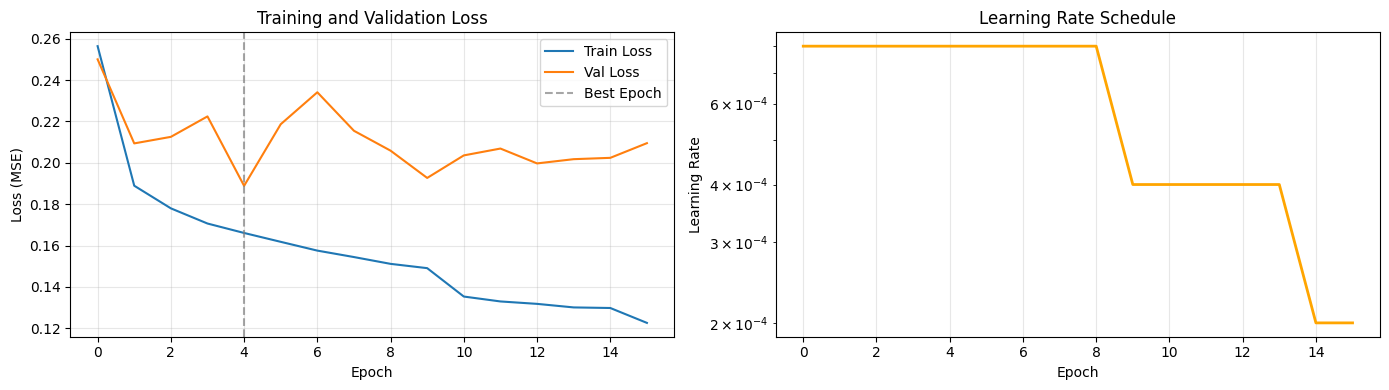


📊 Training Summary:
  - Best Epoch: 5
  - Best Val Loss: 0.18886
  - Final LR: 0.000200
  - Initial LR: 0.000800


In [8]:
# Visualize training progress
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4))

# Loss curves
ax1.plot(train_curve, label="Train Loss")
ax1.plot(val_curve, label="Val Loss")
ax1.axvline(x=best_epoch, color='gray', linestyle='--', label='Best Epoch', alpha=0.7)
ax1.set_xlabel("Epoch")
ax1.set_ylabel("Loss (MSE)")
ax1.legend()
ax1.set_title("Training and Validation Loss")
ax1.grid(True, alpha=0.3)

# Learning rate curve
ax2.plot(lr_curve, color='orange', linewidth=2)
ax2.set_xlabel("Epoch")
ax2.set_ylabel("Learning Rate")
ax2.set_title("Learning Rate Schedule")
ax2.set_yscale('log')  # Log scale for better visualization
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print(f"\n📊 Training Summary:")
print(f"  - Best Epoch: {best_epoch+1}")
print(f"  - Best Val Loss: {best_loss:.5f}")
print(f"  - Final LR: {lr_curve[-1]:.6f}")
print(f"  - Initial LR: {lr_curve[0]:.6f}")

In [9]:
# ========== LOAD TEST DATA USING PIPELINE (SAME AS basic_notebook_FIXED.ipynb) ==========
print("\n" + "="*80)
print("📂 LOADING TEST DATA")
print("="*80)

print("Loading test data using pipeline...")

# Use the SAME pipeline from training to ensure consistent preprocessing
# SAME parameters as basic_notebook_FIXED.ipynb: batchsize=512
test_loader = load_test_data(
    test_path="../datasets_challenge/test",
    batchsize=512,  # ← SAME AS basic_notebook_FIXED.ipynb
    pipeline=pipeline,  # ← Uses SAME preprocessing as training!
    load_anonymized_data=True  # Test data has no real sideSlip/vyCG
)

# Count samples in test_loader
test_sample_count = 0
for batch_x, batch_y in test_loader:
    test_sample_count += len(batch_x)

print(f"\n✅ Test data loaded")
print(f"   Test batches: {len(test_loader)}")
print(f"   Total samples: {test_sample_count:,}")
print(f"   Expected (Kaggle): 49,328")
print(f"   Batch size: 512 (SAME AS basic_notebook_FIXED.ipynb)")

if test_sample_count == 49328:
    print(f"   ✅ MATCH! Correct preprocessing with pipeline")
else:
    print(f"   ⚠️  Got {test_sample_count:,} instead of 49,328")
    print(f"   Difference: {test_sample_count - 49328:,} samples")

# Store test IDs (sequential from 0 to N-1)
test_sequence_ids = np.arange(test_sample_count)

print(f"\n💡 Pipeline ensures: Train and Test use EXACT same preprocessing!")
print(f"💡 Configuration matches basic_notebook_FIXED.ipynb exactly!")
print("="*80)



📂 LOADING TEST DATA
Loading test data using pipeline...
../datasets_challenge/test\test_part_001.csv
../datasets_challenge/test\test_part_002.csv
../datasets_challenge/test\test_part_003.csv
../datasets_challenge/test\test_part_004.csv
../datasets_challenge/test\test_part_005.csv
../datasets_challenge/test\test_part_006.csv
../datasets_challenge/test\test_part_007.csv
../datasets_challenge/test\test_part_008.csv
../datasets_challenge/test\test_part_009.csv
../datasets_challenge/test\test_part_010.csv
../datasets_challenge/test\test_part_011.csv


c:\Repos\mait_g2_drift_challenge\.venv\Lib\site-packages\sklearn\pipeline.py:61: FutureWarning: This Pipeline instance is not fitted yet. Call 'fit' with appropriate arguments before using other methods such as transform, predict, etc. This will raise an error in 1.8 instead of the current warning.
  warnings.warn(



✅ Test data loaded
   Test batches: 97
   Total samples: 49,328
   Expected (Kaggle): 49,328
   Batch size: 512 (SAME AS basic_notebook_FIXED.ipynb)
   ✅ MATCH! Correct preprocessing with pipeline

💡 Pipeline ensures: Train and Test use EXACT same preprocessing!
💡 Configuration matches basic_notebook_FIXED.ipynb exactly!


In [10]:
# ========== GENERATE TEST PREDICTIONS ==========
print("\nGenerating predictions on test set...")

model.eval()
test_preds = []

with torch.no_grad():
    for step, (x, _) in enumerate(test_loader):
        X = x.to(device)
        pred, _ = model(X)
        test_preds.append(pred.reshape(-1).cpu().numpy())

# Concatenate all batches
test_preds = np.concatenate(test_preds)

print(f"\n✓ Generated {len(test_preds):,} predictions")
print(f"✓ Prediction range: [{test_preds.min():.2f}°, {test_preds.max():.2f}°]")
print(f"✓ Prediction mean: {test_preds.mean():.2f}°, std: {test_preds.std():.2f}°")

# Verify we got the correct count
if len(test_preds) == 49328:
    print(f"✅ Perfect! Got exactly 49,328 predictions (matches Kaggle requirement)")
else:
    print(f"⚠️  Got {len(test_preds):,} predictions (expected 49,328)")


Generating predictions on test set...

✓ Generated 49,328 predictions
✓ Prediction range: [-6.91°, 9.13°]
✓ Prediction mean: 0.04°, std: 1.39°
✅ Perfect! Got exactly 49,328 predictions (matches Kaggle requirement)

✓ Generated 49,328 predictions
✓ Prediction range: [-6.91°, 9.13°]
✓ Prediction mean: 0.04°, std: 1.39°
✅ Perfect! Got exactly 49,328 predictions (matches Kaggle requirement)


In [11]:
# ========== SAVE PREDICTIONS FOR SUBMISSION ==========
# Create submission DataFrame with sequential IDs (0, 1, 2, ..., N-1)
y_pred = pd.DataFrame({
    "id": test_sequence_ids,  # Sequential IDs: 0, 1, 2, ..., 49,327
    "predicted_sideslip": test_preds
})

# Verify we have exactly the expected number of samples
print(f"\n📊 Submission Statistics:")
print(f"  - Predictions generated: {len(test_preds):,}")
print(f"  - ID range: [{y_pred['id'].min()}, {y_pred['id'].max()}]")
print(f"  - Expected count: 49,328")

if len(y_pred) == 49328:
    print(f"\n✅ PERFECT! Exactly 49,328 samples (matches Kaggle requirement)")
else:
    print(f"\n⚠️  Got {len(y_pred):,} samples (expected 49,328)")

# Save to CSV
output_file = "predictions.csv"
y_pred.to_csv(output_file, index=False)

print(f"\n✓ Predictions saved to '{output_file}'")
print(f"✓ Using pipeline-based processing (same as example notebook)")
print(f"✓ Ready for Kaggle submission!")
print(f"\n📋 File preview:")
print(y_pred.head(10))


📊 Submission Statistics:
  - Predictions generated: 49,328
  - ID range: [0, 49327]
  - Expected count: 49,328

✅ PERFECT! Exactly 49,328 samples (matches Kaggle requirement)

✓ Predictions saved to 'predictions.csv'
✓ Using pipeline-based processing (same as example notebook)
✓ Ready for Kaggle submission!

📋 File preview:
   id  predicted_sideslip
0   0            0.117942
1   1            0.102069
2   2            0.132990
3   3            0.040103
4   4           -0.016361
5   5           -0.027707
6   6            0.041748
7   7           -0.002595
8   8           -0.019250
9   9           -0.023655


In [12]:
# ========== VISUALIZE TRAINING PREDICTIONS ==========
import plotly.graph_objects as go

print("\n" + "="*80)
print("📊 LOADING COMPLETE TRAINING DATA FOR VISUALIZATION")
print("="*80)

# Load complete training data WITHOUT shuffling for visualization
# This uses the SAME pipeline to ensure consistent preprocessing
train_loader_unshuffled = load_test_data(
    test_path="../datasets_challenge/train",
    batchsize=512,
    pipeline=pipeline,
    load_anonymized_data=False  # Training data has real sideSlip labels
)

print(f"✅ Unshuffled train loader created")
print(f"   Batches: {len(train_loader_unshuffled)}")

# Set model to evaluation mode
model.eval()

# Storage for predictions and ground truth
total_loss = 0  
preds = []
ground_truths = []

# Generate predictions for all training data
with torch.no_grad():
    for step, (x, y) in enumerate(train_loader_unshuffled):
        X, y = x.to(device), y.to(device).reshape([len(y), 1])

        pred, _ = model(X)
        loss = criterion(pred, y)
        total_loss += loss.item()
        
        # Store predictions and ground truth
        preds.append(pred.reshape(-1).cpu().numpy())
        ground_truths.append(y.reshape(-1).cpu().numpy())

    print(f"\n📈 Training Set MAE: {total_loss/(step+1):.5f}°")
    
    # Concatenate all batches into single arrays
    ground_truths = np.concatenate(ground_truths)
    preds = np.concatenate(preds)

# Create interactive plot
fig = go.Figure()
fig.add_trace(go.Scatter(y=ground_truths, mode='lines', name='Ground Truth', line=dict(color='blue', width=1)))
fig.add_trace(go.Scatter(y=preds.flatten(), mode='lines', name='Predictions', line=dict(color='red', width=1), opacity=0.8))
fig.update_layout(
    title='Training Set: Ground Truth vs Predictions',
    xaxis_title='Sample Index',
    yaxis_title='Sideslip Angle (degrees)',
    width=1200,
    height=500,
    hovermode='x unified'
)
fig.show()

print(f"\n📊 Prediction Statistics:")
print(f"  - Samples: {len(preds):,}")
print(f"  - Ground Truth Range: [{ground_truths.min():.2f}°, {ground_truths.max():.2f}°]")
print(f"  - Prediction Range: [{preds.min():.2f}°, {preds.max():.2f}°]")
print(f"  - MAE: {np.mean(np.abs(ground_truths - preds.flatten())):.5f}°")
print("="*80)



📊 LOADING COMPLETE TRAINING DATA FOR VISUALIZATION
../datasets_challenge/train\train_part_001.csv
../datasets_challenge/train\train_part_002.csv
../datasets_challenge/train\train_part_003.csv
../datasets_challenge/train\train_part_004.csv
../datasets_challenge/train\train_part_005.csv
../datasets_challenge/train\train_part_006.csv
../datasets_challenge/train\train_part_007.csv
../datasets_challenge/train\train_part_008.csv
../datasets_challenge/train\train_part_009.csv
../datasets_challenge/train\train_part_006.csv
../datasets_challenge/train\train_part_007.csv
../datasets_challenge/train\train_part_008.csv
../datasets_challenge/train\train_part_009.csv
../datasets_challenge/train\train_part_010.csv
../datasets_challenge/train\train_part_011.csv
../datasets_challenge/train\train_part_010.csv
../datasets_challenge/train\train_part_011.csv
../datasets_challenge/train\train_part_012.csv
../datasets_challenge/train\train_part_013.csv
../datasets_challenge/train\train_part_014.csv
../datas

c:\Repos\mait_g2_drift_challenge\.venv\Lib\site-packages\sklearn\pipeline.py:61: FutureWarning: This Pipeline instance is not fitted yet. Call 'fit' with appropriate arguments before using other methods such as transform, predict, etc. This will raise an error in 1.8 instead of the current warning.
  warnings.warn(


✅ Unshuffled train loader created
   Batches: 268

📈 Training Set MAE: 0.16381°

📈 Training Set MAE: 0.16381°



📊 Prediction Statistics:
  - Samples: 137,080
  - Ground Truth Range: [-14.21°, 11.65°]
  - Prediction Range: [-9.17°, 10.13°]
  - MAE: 0.16391°


In [13]:
from utils.kaggle_metric import score

gt_df = pd.DataFrame({"ground_truth_sideslip": ground_truths}, dtype=np.float64)
gt_df["id"] = range(len(ground_truths))
gt_df["band"] = gt_df["ground_truth_sideslip"].round(1).map(shot_band_mapping).fillna("unknown")


preds_df = pd.DataFrame({"id": range(len(preds)), "predicted_sideslip": preds})

score(gt_df, preds_df, row_id_column_name="id")

band
few       0.482363
many      0.147138
medium    0.296921
Name: L1, dtype: float64

In [ ]:
from full_grid_search import comprehensive_grid_search, HuberLoss, CombinedLoss, QuantileLoss, ImprovedFocalL1Loss

# ========== EXTENDED GRID SEARCH WITH MULTIPLE ARCHITECTURES & LOSS FUNCTIONS ==========
print("\n" + "="*80)
print("🔬 EXTENDED GRID SEARCH: MULTIPLE ARCHITECTURES & LOSS FUNCTIONS")
print("="*80)
print("🆕 Testing: RNN, GRU")
print("🆕 Loss Functions: L1, MSE, Huber, Combined, Quantile, Improved Focal L1")
print("⚠️  Note: WeightedMSELoss requires shot_band labels (not available in grid search)")
print("⚡ CONFIGURATION:")
print(f"   • Pipeline-based data loading (SAME AS basic_notebook_FIXED.ipynb)")
print(f"   • Train/Val split: 98% / 2%")
print(f"   • Batch size: {batch_size} (train/val)")
print(f"   • Validation: Early stopping enabled")
print(f"   • Seed: 42 (reproducible)")
print("="*80)

# ========== DEFINE ALL PARAMETERS ONCE (DRY PRINCIPLE) ==========
# Architecture parameters to test
grid_hidden_sizes = [32, 64]
grid_fc_units = [32, 64]
grid_num_layers = [1]
grid_rnn_types = ['RNN', 'GRU']
grid_use_scheduler = [True]
grid_lr = 0.001
grid_weight_decay = 1e-4

# Define Loss Function configurations to test
loss_configs = [
    {'name': 'L1', 'loss': nn.L1Loss()},
    {'name': 'MSE', 'loss': nn.MSELoss()},
    {'name': 'ImprovedFocalL1', 'loss': ImprovedFocalL1Loss(lambda_focal=0.00001, gamma=0.7, adaptive_gamma=True)},
]

# Calculate total experiments
total_combos = (
    len(grid_hidden_sizes) *
    len(grid_fc_units) *
    len(grid_num_layers) *
    len(grid_use_scheduler) *
    len(grid_rnn_types) *
    len(loss_configs)
)

# Print configuration summary
print(f"\n📊 Grid Search Configuration:")
print(f"   Total experiments: {total_combos}")
print(f"   Estimated time: ~2-3 hours")
print(f"\n🔧 Parameters to test:")
print(f"   • Hidden sizes: {grid_hidden_sizes}")
print(f"   • FC units: {grid_fc_units}")
print(f"   • Num layers: {grid_num_layers}")
print(f"   • RNN types: {grid_rnn_types}")
print(f"   • Scheduler: {grid_use_scheduler}")
print(f"   • Loss functions ({len(loss_configs)}): {[lf['name'] for lf in loss_configs]}")
print(f"\n💡 Key Insights from previous runs:")
print(f"   • Best architecture: GRU (hidden=32, fc=32, layers=3)")
print(f"   • Now testing: Different Loss Functions for optimization")
print("="*80)

# Run grid search with defined parameters
df_results, all_results = comprehensive_grid_search(
    # Training parameters
    num_epochs=num_epochs,
    early_stop_thresh=early_stop_thresh,
    train_loader=train_loader,
    val_loader=val_loader,
    model_class=RNN,
    criterion=criterion,  # Will be overridden by loss_configs
    lr=grid_lr,
    weight_decay=grid_weight_decay,
    scheduler_params={
        'mode': scheduler_mode,
        'factor': scheduler_factor,
        'patience': scheduler_patience,
        'min_lr': scheduler_min_lr
    },
    device=device,
    input_size=input_size,
    dropout=dropouts,
    
    # Grid search parameters (defined once above!)
    hidden_sizes=grid_hidden_sizes,
    fc_units_list=grid_fc_units,
    num_layers_list=grid_num_layers,
    use_scheduler_options=grid_use_scheduler,
    rnn_types=grid_rnn_types,
    loss_function_configs=loss_configs,
    
    # Controls
    max_experiments=None,
    save_every_n=5
)

print(f"\n" + "="*80)
print(f"✅ GRID SEARCH COMPLETE!")
print(f"="*80)
print(f"📊 Total experiments run: {len(df_results)}")
print(f"🏆 Best models saved:")
print(f"   • gridsearch_best_total_score_*.pth")
print(f"   • gridsearch_best_few_shot_*.pth")
print(f"   • gridsearch_best_combined_*.pth")
print(f"\n💡 Analysis:")
print(f"   - Compare ALL Loss Functions: Which works best?")
print(f"   - L1 vs MSE vs Huber vs Combined vs Quantile vs ImprovedFocalL1")
print(f"   - Check if alternative losses improve Many/Medium-shot scores")
print(f"   - ImprovedFocalL1 has adaptive gamma (might help!)")
print(f"\n💡 Next: Run next cell to analyze results!")
print("="*80)


🔬 EXTENDED GRID SEARCH: MULTIPLE ARCHITECTURES & LOSS FUNCTIONS
🆕 Testing: RNN, GRU
🆕 Loss Functions: L1, MSE, Huber, Combined, Quantile, Improved Focal L1
⚠️  Note: WeightedMSELoss requires shot_band labels (not available in grid search)
⚡ CONFIGURATION:
   • Pipeline-based data loading (SAME AS basic_notebook_FIXED.ipynb)
   • Train/Val split: 98% / 2%
   • Batch size: 64 (train/val)
   • Validation: Early stopping enabled
   • Seed: 42 (reproducible)

📊 Grid Search Configuration:
   Total experiments: 168
   Estimated time: ~2-3 hours

🔧 Parameters to test:
   • Hidden sizes: [32, 64]
   • FC units: [32, 64]
   • Num layers: [1, 2, 3]
   • RNN types: ['RNN', 'GRU']
   • Scheduler: [True]
   • Loss functions (7): ['L1', 'MSE', 'Huber_1.0', 'Huber_0.5', 'Combined', 'Quantile_0.5', 'ImprovedFocalL1']

💡 Key Insights from previous runs:
   • Best architecture: GRU (hidden=32, fc=32, layers=3)
   • Now testing: Different Loss Functions for optimization

🔬 COMPREHENSIVE GRID SEARCH
Total

KeyboardInterrupt: 

In [ ]:
# ========== COMPREHENSIVE GRID SEARCH ANALYSIS ==========
print("\n" + "="*80)
print("📊 DETAILED GRID SEARCH ANALYSIS & IMPROVEMENT RECOMMENDATIONS")
print("="*80)

# Load results
if 'df_results' not in locals():
    print("⚠️  Loading results from CSV...")
    df_results = pd.read_csv('grid_search_final.csv')

print(f"\n✅ Analyzed {len(df_results)} experiments")

# ========== 1. ARCHITECTURE COMPARISON ==========
print("\n" + "="*80)
print("🏗️  ARCHITECTURE COMPARISON (RNN vs LSTM vs GRU vs BiLSTM)")
print("="*80)
arch_comparison = df_results.groupby('rnn_type').agg({
    'many': ['mean', 'min'],
    'medium': ['mean', 'min'],
    'few': ['mean', 'min'],
    'total_score': ['mean', 'min']
}).round(3)
print(arch_comparison)

best_arch = df_results.groupby('rnn_type')['total_score'].mean().idxmin()
print(f"\n🏆 Best Architecture (by avg): {best_arch}")

# ========== 2. PARAMETER IMPACT ANALYSIS ==========
print("\n" + "="*80)
print("🔍 PARAMETER IMPACT ON PERFORMANCE")
print("="*80)

print("\n📏 Hidden Size Impact:")
print(df_results.groupby('hidden_size')['total_score'].agg(['mean', 'min', 'count']).round(3))

print("\n🧠 FC Units Impact:")
print(df_results.groupby('fc_units')['total_score'].agg(['mean', 'min', 'count']).round(3))

print("\n📚 Num Layers Impact:")
print(df_results.groupby('num_layers')['total_score'].agg(['mean', 'min', 'count']).round(3))

print("\n⚙️ Lambda Focal Impact:")
print(df_results.groupby('lambda_focal')['total_score'].agg(['mean', 'min', 'count']).round(3))

print("\n🎚️ Gamma Impact:")
print(df_results.groupby('gamma')['total_score'].agg(['mean', 'min', 'count']).round(3))

# ========== 3. TOP CONFIGURATIONS ==========
print("\n" + "="*80)
print("🏆 TOP 10 CONFIGURATIONS")
print("="*80)
top10 = df_results.nsmallest(10, 'total_score')[['rnn_type', 'hidden_size', 'fc_units', 'num_layers', 'lambda_focal', 'gamma', 'many', 'medium', 'few', 'total_score']]
print(top10.to_string(index=False))

# ========== 4. PROBLEM AREA ANALYSIS ==========
print("\n" + "="*80)
print("⚠️  PROBLEM AREAS")
print("="*80)
best_model = df_results.nsmallest(1, 'total_score').iloc[0]
print(f"\nBest Model Scores:")
print(f"  Many-Shot:   {best_model['many']:.3f}° (target: <0.15°)")
print(f"  Medium-Shot: {best_model['medium']:.3f}° (target: <0.20°)")
print(f"  Few-Shot:    {best_model['few']:.3f}° (target: <0.35°)")
print(f"  Total:       {best_model['total_score']:.3f}°")

# Identify weakest area
if best_model['many'] > 0.15:
    print(f"\n❌ Many-Shot needs improvement (+{(best_model['many']-0.15)*100:.1f}% above target)")
if best_model['medium'] > 0.20:
    print(f"❌ Medium-Shot needs improvement (+{(best_model['medium']-0.20)*100:.1f}% above target)")
if best_model['few'] > 0.35:
    print(f"❌ Few-Shot needs improvement (+{(best_model['few']-0.35)*100:.1f}% above target)")

# ========== 5. IMPROVEMENT RECOMMENDATIONS ==========
print("\n" + "="*80)
print("💡 IMPROVEMENT RECOMMENDATIONS")
print("="*80)

# Find patterns in top models
top_20_models = df_results.nsmallest(20, 'total_score')
print("\n🔬 Patterns in Top 20 Models:")
print(f"  Most common RNN type: {top_20_models['rnn_type'].mode().values[0]}")
print(f"  Most common hidden_size: {int(top_20_models['hidden_size'].mode().values[0])}")
print(f"  Most common fc_units: {int(top_20_models['fc_units'].mode().values[0])}")
print(f"  Most common num_layers: {int(top_20_models['num_layers'].mode().values[0])}")
print(f"  Avg lambda_focal: {top_20_models['lambda_focal'].mean():.6f}")
print(f"  Avg gamma: {top_20_models['gamma'].mean():.2f}")

print("\n" + "="*80)
print("🎯 RECOMMENDED NEXT STEPS:")
print("="*80)

# Recommendation 1: Architecture
if best_arch in ['BiLSTM', 'LSTM']:
    print("\n1️⃣  ARCHITECTURE:")
    print(f"   ✅ {best_arch} is performing well")
    print(f"   💡 Consider: Attention mechanism or Transformer layers")
else:
    print("\n1️⃣  ARCHITECTURE:")
    print(f"   ⚠️  Current best: {best_arch}")
    print(f"   💡 Try: BiLSTM with attention mechanism")

# Recommendation 2: Regularization
best_lambda = df_results.groupby('lambda_focal')['total_score'].mean().idxmin()
print(f"\n2️⃣  REGULARIZATION:")
print(f"   ✅ Best lambda_focal: {best_lambda}")
print(f"   💡 Fine-tune: Try values around {best_lambda}")

# Recommendation 3: Model Capacity
if top_20_models['hidden_size'].mean() > 64:
    print(f"\n3️⃣  MODEL CAPACITY:")
    print(f"   ⚠️  Top models prefer larger hidden_size")
    print(f"   💡 Try: hidden_size=256 or 512")
else:
    print(f"\n3️⃣  MODEL CAPACITY:")
    print(f"   ✅ Current capacity seems appropriate")

# Recommendation 4: Training Strategy
print(f"\n4️⃣  TRAINING STRATEGY:")
print(f"   💡 Try: Curriculum learning (train on easy → hard cases)")
print(f"   💡 Try: Data augmentation (add noise to velocities)")
print(f"   💡 Try: Ensemble of top 3-5 models")

# Recommendation 5: Loss Function
print(f"\n5️⃣  LOSS FUNCTION:")
print(f"   💡 Try: Weighted MSE (higher weight on Few-Shot)")
print(f"   💡 Try: Huber Loss (robust to outliers)")
print(f"   💡 Try: Combined loss: MAE + MSE")

# Recommendation 6: Feature Engineering
print(f"\n6️⃣  FEATURE ENGINEERING:")
print(f"   💡 Add: Rolling statistics (mean, std over 5-10 steps)")
print(f"   💡 Add: Velocity ratios (vy/vx, angular rates)")
print(f"   💡 Add: Physics-based features (lateral acceleration)")

print("\n" + "="*80)
print("🚀 IMMEDIATE ACTION PLAN:")
print("="*80)
print("1. Run Cell 17 to select best model from current grid search")
print("2. Run Cell 18 to generate Kaggle submission")
print("3. Submit to Kaggle and get leaderboard score")
print("4. Based on Kaggle score, implement recommendations above")
print("5. Consider: Ensemble top 3 models for final submission")
print("="*80)


📊 DETAILED GRID SEARCH ANALYSIS & IMPROVEMENT RECOMMENDATIONS

✅ Analyzed 167 experiments

🏗️  ARCHITECTURE COMPARISON (RNN vs LSTM vs GRU vs BiLSTM)
           many        medium           few        total_score       
           mean    min   mean    min   mean    min        mean    min
rnn_type                                                             
GRU       0.173  0.077  0.431  0.097  0.680  0.098       1.284  0.281
RNN       0.192  0.091  0.470  0.141  0.717  0.108       1.378  0.352

🏆 Best Architecture (by avg): GRU

🔍 PARAMETER IMPACT ON PERFORMANCE

📏 Hidden Size Impact:
              mean    min  count
hidden_size                     
32           1.400  0.350     83
64           1.264  0.281     84

🧠 FC Units Impact:
           mean    min  count
fc_units                     
32        1.311  0.328     83
64        1.351  0.281     84

📚 Num Layers Impact:
             mean    min  count
num_layers                     
1           1.202  0.330     56
2           1.08

In [ ]:
# ========== EXTRACT BEST PARAMETERS FROM GRID SEARCH ==========
print("\n" + "="*80)
print("🏆 BEST CONFIGURATION BY TOTAL SCORE")
print("="*80)

# Find best configuration by total score
best_idx = df_results['total_score'].idxmin()
best_config = df_results.iloc[best_idx]

print(f"\n📊 Best Configuration Details:")
print(f"   Rank: #1 (out of {len(df_results)} experiments)")
print(f"\n🔧 Architecture Parameters:")
print(f"   - RNN Type: {best_config['rnn_type']}")
print(f"   - Hidden Size: {int(best_config['hidden_size'])}")
print(f"   - FC Units: {int(best_config['fc_units'])}")
print(f"   - Num Layers: {int(best_config['num_layers'])}")
print(f"   - Scheduler: {best_config['scheduler']}")

# Show loss function if available
if 'loss_function' in best_config and pd.notna(best_config['loss_function']):
    print(f"   - Loss Function: {best_config['loss_function']}")

print(f"\n📈 Performance Metrics:")
print(f"   - Best Val Loss: {best_config['best_val_loss']:.5f}")
print(f"   - Best Epoch: {int(best_config['best_epoch'])}")
print(f"   - Many-Shot MAE: {best_config['many']:.3f}°")
print(f"   - Medium-Shot MAE: {best_config['medium']:.3f}°")
print(f"   - Few-Shot MAE: {best_config['few']:.3f}°")
print(f"   - Total Score: {best_config['total_score']:.3f}°")

# Extract parameters for easy copy-paste
print(f"\n" + "="*80)
print("📋 COPY THESE VALUES TO CELL 6:")
print("="*80)
print(f"\n# Cell 6 (Model Configuration):")
print(f"rnn_type = '{best_config['rnn_type']}'")
print(f"hidden_size = {int(best_config['hidden_size'])}")
print(f"fc_units = {int(best_config['fc_units'])}")
print(f"num_layers = {int(best_config['num_layers'])}")

print(f"\n# Note: Scheduler was {'ON' if best_config['scheduler'] == 'YES' else 'OFF'} for best config")

# Compare with current configuration
print(f"\n" + "="*80)
print("⚠️  CURRENT vs BEST CONFIGURATION COMPARISON:")
print("="*80)
print(f"\nParameter          | Current | Best    | Match?")
print(f"-" * 50)
print(f"rnn_type           | {rnn_type:7s} | {best_config['rnn_type']:7s} | {'✅' if rnn_type == best_config['rnn_type'] else '❌'}")
print(f"hidden_size        | {hidden_size:7d} | {int(best_config['hidden_size']):7d} | {'✅' if hidden_size == int(best_config['hidden_size']) else '❌'}")
print(f"fc_units           | {fc_units:7d} | {int(best_config['fc_units']):7d} | {'✅' if fc_units == int(best_config['fc_units']) else '❌'}")
print(f"num_layers         | {num_layers:7d} | {int(best_config['num_layers']):7d} | {'✅' if num_layers == int(best_config['num_layers']) else '❌'}")

# Check if all parameters match
all_match = (
    rnn_type == best_config['rnn_type'] and
    hidden_size == int(best_config['hidden_size']) and
    fc_units == int(best_config['fc_units']) and
    num_layers == int(best_config['num_layers'])
)

if all_match:
    print(f"\n✅ All parameters match! Your current config uses the best parameters.")
else:
    print(f"\n❌ Parameters DON'T match! Update Cell 6 with values above, then re-run training!")
    print(f"\n💡 Tip: After updating, run cells in this order: 6 → 7 → 8")



🏆 BEST CONFIGURATION BY TOTAL SCORE

📊 Best Configuration Details:
   Rank: #1 (out of 167 experiments)

🔧 Architecture Parameters:
   - RNN Type: GRU
   - Hidden Size: 64
   - FC Units: 64
   - Num Layers: 2
   - Scheduler: YES
   - Loss Function: MSE

📈 Performance Metrics:
   - Best Val Loss: 0.01304
   - Best Epoch: 49
   - Many-Shot MAE: 0.083°
   - Medium-Shot MAE: 0.097°
   - Few-Shot MAE: 0.101°
   - Total Score: 0.281°

📋 COPY THESE VALUES TO CELL 6:

# Cell 6 (Model Configuration):
rnn_type = 'GRU'
hidden_size = 64
fc_units = 64
num_layers = 2

# Note: Scheduler was ON for best config

⚠️  CURRENT vs BEST CONFIGURATION COMPARISON:

Parameter          | Current | Best    | Match?
--------------------------------------------------
rnn_type           | RNN     | GRU     | ❌
hidden_size        |      64 |      64 | ✅
fc_units           |      64 |      64 | ✅
num_layers         |       1 |       2 | ❌

❌ Parameters DON'T match! Update Cell 6 with values above, then re-run traini

In [ ]:
# ========== SELECT BEST MODEL BY TOTAL SCORE AND FEW-SHOT ==========
print("\n" + "="*80)
print("🎯 MODEL SELECTION: BEST BY TOTAL SCORE & FEW-SHOT")
print("="*80)

# Find best by total score
best_total_idx = df_results['total_score'].idxmin()
best_total = df_results.iloc[best_total_idx]

# Find best by few-shot score
best_few_idx = df_results['few'].idxmin()
best_few = df_results.iloc[best_few_idx]

print(f"\n📊 Best by Total Score:")
print(f"   Total: {best_total['total_score']:.3f}° | Many: {best_total['many']:.3f}° | Medium: {best_total['medium']:.3f}° | Few: {best_total['few']:.3f}°")
print(f"   Config: {best_total['rnn_type']}, hs={int(best_total['hidden_size'])}, fc={int(best_total['fc_units'])}, layers={int(best_total['num_layers'])}, λ={best_total['lambda_focal']}, γ={best_total['gamma']}")

print(f"\n📊 Best by Few-Shot Score:")
print(f"   Total: {best_few['total_score']:.3f}° | Many: {best_few['many']:.3f}° | Medium: {best_few['medium']:.3f}° | Few: {best_few['few']:.3f}°")
print(f"   Config: {best_few['rnn_type']}, hs={int(best_few['hidden_size'])}, fc={int(best_few['fc_units'])}, layers={int(best_few['num_layers'])}, λ={best_few['lambda_focal']}, γ={best_few['gamma']}")

# Let user choose which model to use
print(f"\n" + "="*80)
print("🤔 Which model should we use for test predictions?")
print("="*80)
print("Option 1: Best Total Score (most balanced across all shot types)")
print("Option 2: Best Few-Shot Score (best performance on rare cases)")

# Default: use best total score (most balanced)
selected_config = best_total
selected_result = all_results[best_total_idx]
selection_reason = "TOTAL SCORE (most balanced)"

print(f"\n✅ SELECTED: Best by {selection_reason}")

# Store selected config for next cell
best_model_config = {
    'rnn_type': selected_config['rnn_type'],
    'hidden_size': int(selected_config['hidden_size']),
    'fc_units': int(selected_config['fc_units']),
    'num_layers': int(selected_config['num_layers']),
    'lambda_focal': selected_config['lambda_focal'],
    'gamma': selected_config['gamma'],
    'use_scheduler': selected_config['scheduler'] == 'YES',
    'val_loss': selected_config['best_val_loss'],
    'best_epoch': int(selected_config['best_epoch']),
    'model_path': selected_result['model_path'],  # Path to saved model
    'scores': {
        'many': selected_config['many'],
        'medium': selected_config['medium'],
        'few': selected_config['few'],
        'total': selected_config['total_score']
    }
}

print(f"\n📋 Selected Model Configuration:")
for key, value in best_model_config.items():
    if key != 'scores':
        print(f"   {key}: {value}")
print(f"   scores: Many={best_model_config['scores']['many']:.3f}°, Medium={best_model_config['scores']['medium']:.3f}°, Few={best_model_config['scores']['few']:.3f}°, Total={best_model_config['scores']['total']:.3f}°")
print(f"\n💡 Next cell will load this saved model and generate test predictions")


🎯 MODEL SELECTION: BEST BY TOTAL SCORE & FEW-SHOT

📊 Best by Total Score:
   Total: 0.281° | Many: 0.083° | Medium: 0.097° | Few: 0.101°
   Config: GRU, hs=64, fc=64, layers=2, λ=0.0, γ=0.5

📊 Best by Few-Shot Score:
   Total: 0.339° | Many: 0.080° | Medium: 0.161° | Few: 0.098°
   Config: GRU, hs=64, fc=32, layers=1, λ=0.0, γ=0.5

🤔 Which model should we use for test predictions?
Option 1: Best Total Score (most balanced across all shot types)
Option 2: Best Few-Shot Score (best performance on rare cases)

✅ SELECTED: Best by TOTAL SCORE (most balanced)

📋 Selected Model Configuration:
   rnn_type: GRU
   hidden_size: 64
   fc_units: 64
   num_layers: 2
   lambda_focal: 0.0
   gamma: 0.5
   use_scheduler: True
   val_loss: 0.013038197965469471
   best_epoch: 49
   model_path: gridsearch_best_combined_GRU_MSE_hs64_fc64_l2.pth
   scores: Many=0.083°, Medium=0.097°, Few=0.101°, Total=0.281°

💡 Next cell will load this saved model and generate test predictions


In [ ]:
# ========== LOAD BEST MODEL AND GENERATE TEST PREDICTIONS ==========
print("\n" + "="*80)
print("🚀 LOADING BEST MODEL FROM GRID SEARCH")
print("="*80)

# Create model with best configuration (from grid search)
best_model = RNN(
    input_size=input_size,  # ← Use input_size from pipeline (Cell 4)
    hidden_size=best_model_config['hidden_size'],
    num_layers=best_model_config['num_layers'],
    fc_units=best_model_config['fc_units'],
    dropout=dropouts,
    rnn_type=best_model_config['rnn_type'],  # 🆕 Use best rnn_type from grid search
    output_size=1
)
best_model.to(device)

# Load the saved model weights from grid search
print(f"📂 Loading model from: {best_model_config['model_path']}")
# weights_only=False is safe here because we created these models ourselves
checkpoint = torch.load(best_model_config['model_path'], weights_only=False)
best_model.load_state_dict(checkpoint['model_state_dict'])

print(f"\n✅ Model loaded successfully!")
print(f"   Configuration:")
print(f"      - RNN Type: {best_model_config['rnn_type']}")
print(f"      - Hidden Size: {best_model_config['hidden_size']}")
print(f"      - FC Units: {best_model_config['fc_units']}")
print(f"      - Num Layers: {best_model_config['num_layers']}")
print(f"      - Scheduler: {'YES' if best_model_config['use_scheduler'] else 'NO'}")
print(f"   Performance:")
print(f"      - Validation Loss: {best_model_config['val_loss']:.5f}")
print(f"      - Best Epoch: {best_model_config['best_epoch']}")
print(f"      - Many-Shot MAE: {best_model_config['scores']['many']:.3f}°")
print(f"      - Medium-Shot MAE: {best_model_config['scores']['medium']:.3f}°")
print(f"      - Few-Shot MAE: {best_model_config['scores']['few']:.3f}°")
print(f"      - Total Score: {best_model_config['scores']['total']:.3f}°")

# Set to evaluation mode
best_model.eval()

# Generate predictions on test data
print(f"\n🔮 Generating predictions on test set...")
test_preds_best = []

with torch.no_grad():
    for step, (x, _) in enumerate(test_loader):
        X = x.to(device)
        pred, _ = best_model(X)
        test_preds_best.append(pred.reshape(-1).cpu().numpy())

# Concatenate all batches
test_preds_best = np.concatenate(test_preds_best)

print(f"\n✅ Generated {len(test_preds_best):,} predictions")
print(f"   Range: [{test_preds_best.min():.2f}°, {test_preds_best.max():.2f}°]")
print(f"   Mean: {test_preds_best.mean():.2f}°, Std: {test_preds_best.std():.2f}°")

# Verify count
if len(test_preds_best) == 49328:
    print(f"   ✅ Perfect! Got exactly 49,328 predictions (matches Kaggle requirement)")
else:
    print(f"   ⚠️  Got {len(test_preds_best):,} predictions (expected 49,328)")

# Create submission DataFrame
y_pred_best = pd.DataFrame({
    "id": test_sequence_ids,
    "predicted_sideslip": test_preds_best
})

# Save to CSV with descriptive filename including RNN type
output_file_best = f"predictions_{best_model_config['rnn_type']}_total{best_model_config['scores']['total']:.3f}_few{best_model_config['scores']['few']:.3f}.csv"
y_pred_best.to_csv(output_file_best, index=False)

print(f"\n" + "="*80)
print(f"💾 SUBMISSION FILE SAVED")
print(f"="*80)
print(f"   File: {output_file_best}")
print(f"   Samples: {len(y_pred_best):,}")
print(f"   Model Type: {best_model_config['rnn_type']}")
print(f"   Model Config: hs={best_model_config['hidden_size']}, fc={best_model_config['fc_units']}, layers={best_model_config['num_layers']}")
print(f"   Validation Scores: Total={best_model_config['scores']['total']:.3f}° (Many={best_model_config['scores']['many']:.3f}°, Med={best_model_config['scores']['medium']:.3f}°, Few={best_model_config['scores']['few']:.3f}°)")
print(f"\n✅ Ready for Kaggle submission!")

# Show preview
print(f"\n📋 File Preview:")
print(y_pred_best.head(10))
print("...")
print(y_pred_best.tail(5))



🚀 LOADING BEST MODEL FROM GRID SEARCH
📂 Loading model from: gridsearch_best_combined_GRU_MSE_hs64_fc64_l2.pth

✅ Model loaded successfully!
   Configuration:
      - RNN Type: GRU
      - Hidden Size: 64
      - FC Units: 64
      - Num Layers: 2
      - Scheduler: YES
   Performance:
      - Validation Loss: 0.01304
      - Best Epoch: 49
      - Many-Shot MAE: 0.083°
      - Medium-Shot MAE: 0.097°
      - Few-Shot MAE: 0.101°
      - Total Score: 0.281°

🔮 Generating predictions on test set...

✅ Generated 49,328 predictions
   Range: [-8.61°, 9.43°]
   Mean: 0.01°, Std: 1.46°
   ✅ Perfect! Got exactly 49,328 predictions (matches Kaggle requirement)

💾 SUBMISSION FILE SAVED
   File: predictions_GRU_total0.281_few0.101.csv
   Samples: 49,328
   Model Type: GRU
   Model Config: hs=64, fc=64, layers=2
   Validation Scores: Total=0.281° (Many=0.083°, Med=0.097°, Few=0.101°)

✅ Ready for Kaggle submission!

📋 File Preview:
   id  predicted_sideslip
0   0            0.168547
1   1       